# 尾部相关性：数据、边缘分布、Copula

本 notebook 是各个复现共用的「机器」的展示与体检，覆盖三层，每一步都先落成 DataFrame 再往下算：

| 层 | 内容 | 产出 |
|---|---|---|
| L0 | 数据提取与质量体检 | 价格表、收益率表、质量表 |
| L1 | 边缘分布与概率积分变换（PIT） | 四种口径并排 |
| L2 | Copula、噪声基准、滚动尾部相关系数 | λ_D / λ_U 序列 |

核心数学在 `tailrisk/`（有 `tests/` 回归测试），这里只做调用、展示与检查。

## 0 · 环境

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tailrisk").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tailrisk import data, marginals as mg, copula as cp

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.unicode_minus": False,
    "font.sans-serif": ["PingFang SC", "Heiti TC", "Arial Unicode MS", "SimHei", "DejaVu Sans"],
})

---
# L0 · 数据

`data.SERIES` 是全部可用标的的登记表。中债指数直接取自中国债券信息网，
股票指数经 AkShare 取自新浪，都免账号、都缓存在 `data/cache/`（不入库）。
同花顺导出文件用 `data.parse_ifind_export` 解析，聚宽用 `data.jq_login`。

In [2]:
NAMES = ["沪深300", "中证500", "上证国债指数", "中债综合财富"]
prices = data.load_prices(NAMES, how="outer")
pd.DataFrame({
    "起点": prices.apply(lambda s: s.first_valid_index()),
    "终点": prices.apply(lambda s: s.last_valid_index()),
    "非空观测": prices.notna().sum(),
})

,起点,终点,非空观测
沪深300,2002-01-04,2026-10-12,6006
中证500,2005-01-04,2026-10-12,5285
上证国债指数,2003-01-02,2026-10-12,5769
中债综合财富,2002-01-04,2026-10-12,6194


外连接保留所有交易日。**不做前向填充**——填充会产生大量零收益（ties），
PIT 时这些 ties 会挤在同一分位，让 Copula 的 MLE 偏向独立解。

收益率用 `data.to_returns`，它显式关掉了 pandas `pct_change` 默认的前向填充
（默认行为会把缺失日变成 0 收益，下一日再跨缺口计收益）。

In [3]:
quality = data.data_quality(prices)
quality

,标的,样本数,起点,终点,年化收益,年化波动,最大回撤,零收益占比,唯一值占比,可用
0,沪深300,6006,2002-01-04,2026-10-12,0.048830,0.242085,-0.723038,0.000000,1.000000,True
1,中证500,5285,2005-01-04,2026-10-12,0.094833,0.283735,-0.724172,0.000000,1.000000,True
2,上证国债指数,5769,2003-01-02,2026-10-12,0.035989,0.012684,-0.104234,0.008842,0.990985,True
3,中债综合财富,6194,2002-01-04,2026-10-12,0.039933,0.016832,-0.035539,0.000161,1.000000,True


**看什么**：

- `零收益占比` > 5% 或 `唯一值占比` < 80% → ties 问题，Copula 会偏向独立解
- `年化收益` 接近票息水平（3–4%）且回撤很小 → 财富指数；接近 0 且震荡 → 净价指数
- `起点` 决定能覆盖哪几次历史危机

In [4]:
returns = data.to_returns(prices)
returns.describe().T[["count", "mean", "std", "min", "max"]]

,count,mean,std,min,max
沪深300,5878.0,0.000250,0.015366,-0.092398,0.093893
中证500,5166.0,0.000434,0.018032,-0.095539,0.098721
上证国债指数,5644.0,0.000141,0.000812,-0.013771,0.010215
中债综合财富,6193.0,0.000157,0.001078,-0.008404,0.009766


---
# L1 · 边缘分布与 PIT

Copula 的输入必须是 (0,1) 上的均匀分布值，先把收益率做概率积分变换。四种口径：

| 口径 | 做法 | 定位 |
|---|---|---|
| `window` | 每个 60 日窗口内单独秩变换 | **主口径**：只用窗口数据，无前视；最贴合中金「使用过去 60 个交易日数据计算」 |
| `empirical` | 全样本秩变换 | 对照；每个点的分位依赖全样本，有前视 |
| `vol_scaled` | 滚动波动率标准化后全样本秩变换 | 中间档 |
| `garch` | GJR-GARCH 滤波后对标准化残差秩变换 | 对照；会剥离波动率联动 |

⚠ 全样本口径下，危机窗口里两边的 u 会同时挤向 0/1 两端，
Copula 会把「波动率同时放大」当成尾部相关；GARCH 口径则相反，可能把要测的东西一起剥掉。

In [5]:
A, B = "沪深300", "中债综合财富"
pair = returns[[A, B]].dropna()

pit_table = pd.DataFrame({
    f"{A}_empirical": mg.pit_empirical(pair[A]),
    f"{B}_empirical": mg.pit_empirical(pair[B]),
    f"{A}_vol_scaled": mg.pit_vol_scaled(pair[A]),
    f"{B}_vol_scaled": mg.pit_vol_scaled(pair[B]),
    f"{A}_garch": mg.pit_garch(pair[A]),
    f"{B}_garch": mg.pit_garch(pair[B]),
})
pit_table.describe().T[["count", "mean", "std", "min", "max"]]

/opt/anaconda3/lib/python3.13/site-packages/arch/univariate/base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.01172. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


,count,mean,std,min,max
沪深300_empirical,5878.0,0.5,0.288651,0.000170,0.999830
中债综合财富_empirical,5878.0,0.5,0.288651,0.000170,0.999830
沪深300_vol_scaled,5848.0,0.5,0.288650,0.000171,0.999829
中债综合财富_vol_scaled,5848.0,0.5,0.288650,0.000171,0.999829
沪深300_garch,5878.0,0.5,0.288651,0.000170,0.999830
中债综合财富_garch,5878.0,0.5,0.288651,0.000170,0.999830


PIT 后的值应近似均匀分布：均值≈0.5、标准差≈0.289。

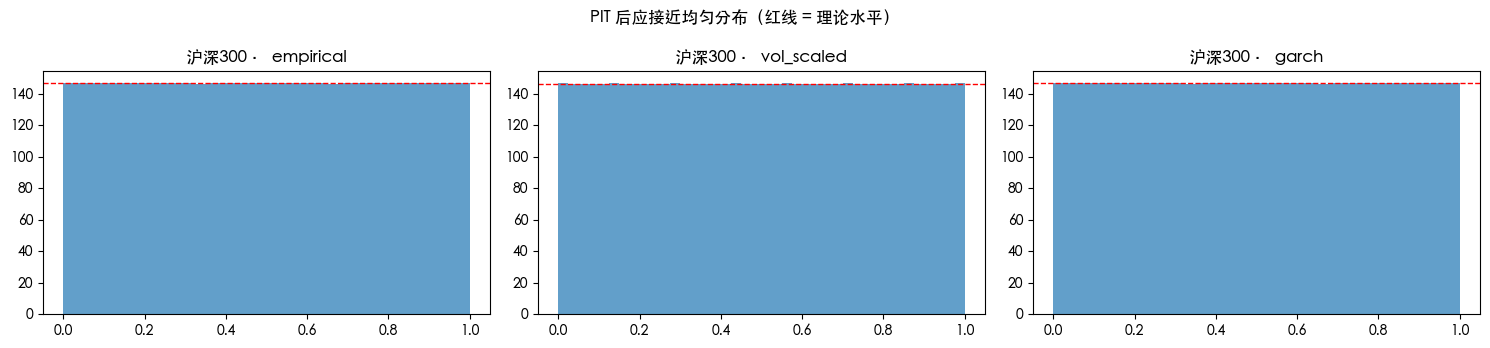

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, kind in zip(axes, ["empirical", "vol_scaled", "garch"]):
    x = pit_table[f"{A}_{kind}"].dropna()
    ax.hist(x, bins=40, alpha=.7)
    ax.axhline(len(x) / 40, color="r", ls="--", lw=1)
    ax.set_title(f"{A} · {kind}")
plt.suptitle("PIT 后应接近均匀分布（红线 = 理论水平）")
plt.tight_layout(); plt.show()

---
# L2 · Copula 与尾部相关性

## L2.1 全样本单次拟合

In [7]:
u, v = mg.rank_pit(pair[A].values), mg.rank_pit(pair[B].values)
cl, gu, ga = cp.ClaytonCopula().fit(u, v), cp.GumbelCopula().fit(u, v), cp.GaussianCopula().fit(u, v)
pd.DataFrame([
    {"copula": "clayton", "参数": cl.theta, "loglik": cl.loglik, "λ_D": cl.lambda_raw, "λ_U": 0.0, "独立性p值": cl.pvalue},
    {"copula": "gumbel", "参数": gu.theta, "loglik": gu.loglik, "λ_D": 0.0, "λ_U": gu.lambda_raw, "独立性p值": gu.pvalue},
    {"copula": "gaussian", "参数": ga.rho, "loglik": ga.loglik, "λ_D": 0.0, "λ_U": 0.0, "独立性p值": np.nan},
])

,copula,参数,loglik,λ_D,λ_U,独立性p值
0,clayton,0.000007,-0.001277,0.0,0.000000,1.0
1,gumbel,1.000006,-0.003045,0.0,0.000008,1.0
2,gaussian,-0.057595,9.765434,0.0,0.000000,NaN


## L2.2 噪声基准 ← 全项目最重要的一张表

任何「测出了尾部相关性」的结论，都必须和「**无尾部相关**的数据下同一统计量的取值」对照。
下面的数据全部来自高斯 copula（尾部相关严格为 0），只改变整体相关系数 ρ 和判零口径。

In [8]:
rows = []
for rule in ["point", "lrtest"]:
    for i, rho in enumerate([0.0, 0.2, 0.3, 0.5]):
        rows.append(cp.noise_baseline(window=60, n_rep=500, rho=rho, seed=10 + i, zero_rule=rule))
pd.DataFrame(rows).set_index(["判零口径", "rho"]).style.format("{:.1%}")

**判读**：

- 点估计口径（中金原文）下，纯独立数据也有约三分之一的窗口 λ_D>0。
- 两种口径下，随 ρ 上升 λ_D>0 和 λ_U>0 的占比都急剧上升 —— Clayton/Gumbel 测的主要是
  「窗口内有没有正相关」，不是「有没有尾部相关」。
- 中金条件（λ_D>0 且 λ_U=0）在 ρ 较高时反而很少成立，因为两边会同时离开边界。

因此实测频率要和 `cp.expected_under_gaussian` 给出的「**相同相关强度**」基准比，
而不是和独立数据比。

## L2.3 滚动尾部相关系数（主口径：窗口内秩变换、点估计判零）

In [9]:
roll = cp.rolling_tail_dependence(pair[A], pair[B], window=60, zero_rule="point")
summary = pd.DataFrame({
    "λ_D": [(roll.lambda_D > 0).mean(), roll.lambda_D[roll.lambda_D > 0].median()],
    "λ_U": [(roll.lambda_U > 0).mean(), roll.lambda_U[roll.lambda_U > 0].median()],
}, index=["大于0的占比", "非零时的中位数"])
summary

,λ_D,λ_U
大于0的占比,0.291631,0.417082
非零时的中位数,0.024197,0.093910


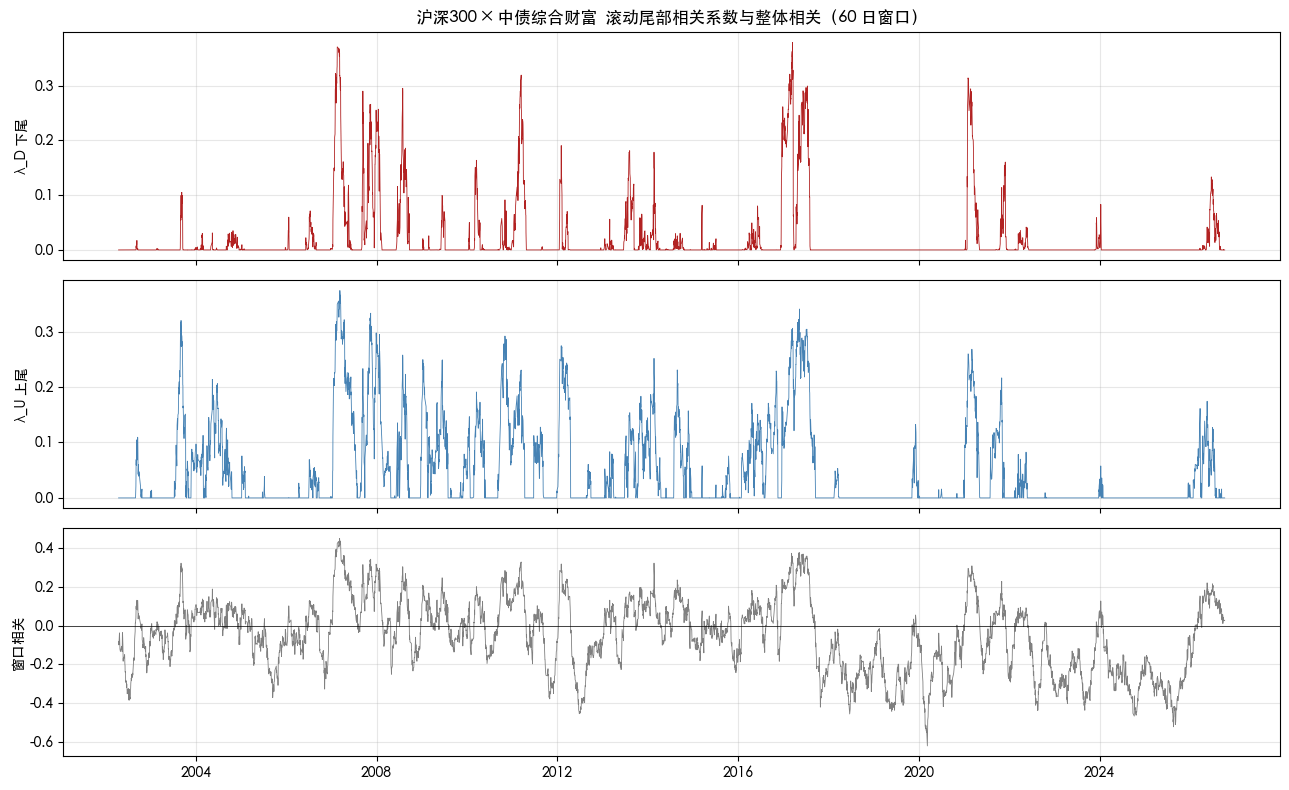

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
axes[0].plot(roll.index, roll.lambda_D, lw=.6, color="firebrick"); axes[0].set_ylabel("λ_D 下尾")
axes[1].plot(roll.index, roll.lambda_U, lw=.6, color="steelblue"); axes[1].set_ylabel("λ_U 上尾")
axes[2].plot(roll.index, roll.ns_corr, lw=.6, color="gray"); axes[2].axhline(0, color="k", lw=.5)
axes[2].set_ylabel("窗口相关")
axes[0].set_title(f"{A} × {B}  滚动尾部相关系数与整体相关（60 日窗口）")
for ax in axes:
    ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

λ 与窗口整体相关几乎同步起落，这就是 L2.2 所说的问题在真实数据上的样子。

## L2.4 尾部不对称诊断

`ll_diff = ll_Clayton − ll_Gumbel` 比两个 λ 各自判零更直接地回答「下尾是否比上尾更强」。
同样要和高斯基准对照：基准的窗口相关系数从实测的 ns_corr 中抽取，
使两边「整体相关强度」的分布一致，差别只剩尾部结构。

In [11]:
null = cp.gaussian_null(window=60, n_sims=3000, rho=roll.ns_corr.values, seed=1)
pd.DataFrame({
    "实测": roll.ll_diff.quantile([.01, .05, .25, .5, .75, .95, .99]),
    "高斯基准": null.ll_diff.quantile([.01, .05, .25, .5, .75, .95, .99]),
})

,实测,高斯基准
0.01,-2.482666,-2.785801
0.05,-1.095305,-1.085873
0.25,-0.005630,-0.000074
0.50,0.000035,0.000042
0.75,0.003324,0.000121
0.95,0.780963,0.949534
0.99,2.209693,2.248599


实测与基准的分位数几乎重合：沪深300 × 中债综合财富上，**没有证据显示下尾相依强于上尾**。

In [12]:
ct = pd.crosstab((roll.lambda_D > 0).map({True: "λ_D>0", False: "λ_D=0"}),
                 (roll.lambda_U > 0).map({True: "λ_U>0", False: "λ_U=0"}))
(ct / ct.values.sum()).style.format("{:.1%}")

lambda_U,λ_U=0,λ_U>0
lambda_D,,
λ_D=0,53.7%,17.2%
λ_D>0,4.6%,24.5%


---
## 小结

机器已就位：数据层、四种 PIT 口径、Copula 与两种判零口径、匹配相关强度的噪声基准。
各篇研报的复现在 `studies/` 下的其他目录。